# Dynamics Under Noise: from an 8-spin Trotter study to a certified 100-qubit kicked-Ising run on IBM Quantum

**Qiskit Fall Fest 2026 · IIIT-Delhi · Track 3: Quantum Simulation** · level targeted: **Advanced**

This notebook covers all three levels of the track. It runs top to bottom. The heavy noisy-simulation sweeps and every real-QPU result load from `results/` by default, so the whole notebook finishes in a few minutes. Set `RECOMPUTE = True` to regenerate the simulations, or `RUN_ON_HARDWARE = True` to resubmit to IBM Quantum.

| Level | What we do | Headline |
|---|---|---|
| 🟢 Beginner | 8-spin TFIM, Lie vs Suzuki Trotter, exact `expm` reference | For Z observables from \|0…0⟩, Lie-Trotter **equals** Suzuki-Trotter exactly. The "why it depends on what you measure" question, proven |
| 🟠 Intermediate | 12-spin TFIM, FakeFez noise, our own TREX + twirling + ZNE, depth cutting | 2nd-order accuracy at 1st-order CZ cost. An error-aware line layout with zero SWAPs |
| 🔴 Advanced | Kicked (Floquet) Ising chain, **100 qubits**, on an IBM Heron QPU | Certified against **exact** solutions at all depths: free fermions + Pfaffians, light cones and Clifford stabilisers |

**Contents**
0. Setup
1. Beginner: getting the simulation right (8 spins)
2. Intermediate: recovering the physics that noise hides (12 spins)
3. Advanced: a 100-qubit kicked-Ising chain on IBM hardware, certified without brute force
4. Performance, limitations and what we would do next
5. Credits and references

## 0 · Setup

Every helper lives in [`ising_lab.py`](ising_lab.py), next to this notebook. That way the analysis and the hardware-submission script ([`hardware/run_hardware.py`](hardware/run_hardware.py)) use exactly the same circuits. On Colab, the first cell clones the repository so the module and the cached results are available.

In [1]:
# On Google Colab, uncomment the next two lines first:
# !pip install -q "qiskit[visualization]==2.5.2" "qiskit-aer==0.17.2" "qiskit-ibm-runtime==0.50.0"
# !git clone -q --depth 1 https://github.com/REPO_OWNER/REPO_NAME && %cd REPO_NAME

RECOMPUTE = False         # True: re-run the noisy-simulator sweeps (~15 min) instead of loading results/
RUN_ON_HARDWARE = False   # True: resubmit the QPU jobs (needs a saved IBM Quantum account and QPU minutes)

In [2]:
import os
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")   # small matrices: avoid BLAS thread oversubscription
import json, math, time, warnings
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm

import qiskit, qiskit_aer, qiskit_ibm_runtime
from qiskit import QuantumCircuit
from qiskit.circuit.library import PauliEvolutionGate
from qiskit.synthesis import LieTrotter, SuzukiTrotter
from qiskit.quantum_info import SparsePauliOp, Statevector

import ising_lab as il

warnings.filterwarnings("ignore", category=DeprecationWarning)
RESULTS = Path("results"); FIGS = Path("figures"); FIGS.mkdir(exist_ok=True)
print("qiskit", qiskit.__version__, "| qiskit-aer", qiskit_aer.__version__, "| qiskit-ibm-runtime", qiskit_ibm_runtime.__version__)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False})
COL = {"exact": "black", "lie": "#1f77b4", "suzuki": "#ff7f0e", "strang": "#2ca02c",
       "raw": "#9e9e9e", "trex": "#8c564b", "twirl": "#9467bd", "zne": "#d62728", "hw": "#d62728"}
def savefig(name):
    plt.savefig(FIGS / f"{name}.png", dpi=160, bbox_inches="tight")

qiskit 2.5.2 | qiskit-aer 0.17.2 | qiskit-ibm-runtime 0.50.0


## 1 · 🟢 Beginner: getting the simulation right (8 spins)

**Model.** Open transverse-field Ising chain, $H = -J\sum_i Z_iZ_{i+1} - h\sum_i X_i$, with $N=8$, $J=h=1$, starting from $|00000000\rangle$ and evolving to $t=2$.

**Exact reference.** We use `scipy.linalg.expm` as the challenge asks: $|\psi(t)\rangle = e^{-iHt}|\psi_0\rangle$ on the $2^8$-dimensional space.

**Product formulas.** Write $H = H_{ZZ} + H_X$. Each part is a sum of *commuting* terms, so $e^{-iH_{ZZ}\tau}$ and $e^{-iH_X\tau}$ are exact products of `RZZ` and `RX` gates. All of the Trotter error comes from splitting between the two groups:

* Lie-Trotter (1st order): $U_1(\Delta t) = e^{-iH_X\Delta t}\,e^{-iH_{ZZ}\Delta t}$
* Suzuki-Trotter (2nd order): $U_2(\Delta t) = e^{-iH_{ZZ}\Delta t/2}\,e^{-iH_X\Delta t}\,e^{-iH_{ZZ}\Delta t/2}$

These are the orderings Qiskit's `LieTrotter` / `SuzukiTrotter` build from our `SparsePauliOp`, which lists the ZZ terms first.

In [3]:
N, J, h, T_FINAL = 8, 1.0, 1.0, 2.0
H = il.tfim_hamiltonian(N, J, h)                     # ZZ terms first, then X terms
Mz_op, Mx_op = il.average_op(N, "Z"), il.average_op(N, "X")
Hm, Mz_m, Mx_m = H.to_matrix(), Mz_op.to_matrix(), Mx_op.to_matrix()
psi0 = np.zeros(2**N, complex); psi0[0] = 1

def exact_state(t):
    return expm(-1j * Hm * t) @ psi0

t_grid = np.linspace(0, T_FINAL, 81)
psi_exact = [exact_state(t) for t in t_grid]
mz_exact = np.array([np.real(np.vdot(p, Mz_m @ p)) for p in psi_exact])
mx_exact = np.array([np.real(np.vdot(p, Mx_m @ p)) for p in psi_exact])

# the same reference via one eigendecomposition (used later for fast dt scans) agrees with expm:
w, V = np.linalg.eigh(Hm); c0 = V.conj().T @ psi0
eig_state = lambda t: V @ (np.exp(-1j * w * t) * c0)
print("max |expm - eigh| over the grid:", max(np.abs(exact_state(t) - eig_state(t)).max() for t in t_grid))

max |expm - eigh| over the grid: 5.0715482659930485e-15


### 1.1 Qiskit Trotter circuits, and a fast engine that reproduces them exactly

We build the circuits with `PauliEvolutionGate` and keep `.decompose(reps=2)`, so the Trotter error stays visible, as the README warns. Scanning hundreds of step sizes with circuits is slow, so `il.TFIMEngine` applies the same factors $e^{-iH_{ZZ}\tau}$ (diagonal) and $e^{-iH_X\tau}$ (one rotation per qubit) directly to a statevector. We check below that it matches the Qiskit circuits to machine precision.

In [4]:
def qiskit_trotter_circuit(H, n_steps, dt, order):
    synth = LieTrotter(reps=1) if order == 1 else SuzukiTrotter(order=2, reps=1)
    qc = QuantumCircuit(H.num_qubits)
    step = PauliEvolutionGate(H, time=dt, synthesis=synth)
    for _ in range(n_steps):
        qc.append(step, range(H.num_qubits))
    return qc.decompose(reps=2)          # keep the Trotter error (see README warning)

engine = il.TFIMEngine(N, J, h)
for order, scheme in ((1, "lie"), (2, "suzuki")):
    for dt, k in ((0.3, 4), (0.17, 9)):
        sv = Statevector(qiskit_trotter_circuit(H, k, dt, order)).data
        me = engine.trajectory(dt, k, scheme)[-1]
        print(f"order {order}, dt={dt}, {k} steps: 1-|<qiskit|engine>| = {1-abs(np.vdot(sv, me)):.1e}")

order 1, dt=0.3, 4 steps: 1-|<qiskit|engine>| = 4.0e-15
order 1, dt=0.17, 9 steps: 1-|<qiskit|engine>| = -1.1e-14
order 2, dt=0.3, 4 steps: 1-|<qiskit|engine>| = 7.0e-15
order 2, dt=0.17, 9 steps: 1-|<qiskit|engine>| = 4.4e-15


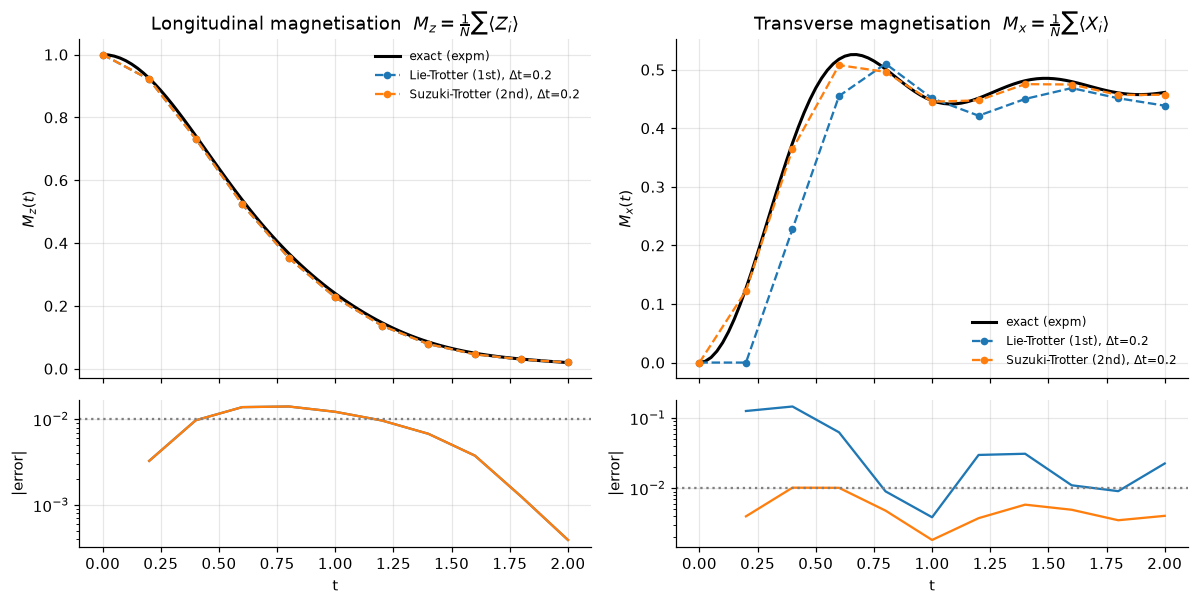

In [5]:
dt_plot = 0.2
k_plot = int(round(T_FINAL / dt_plot))
traj = {s: engine.trajectory(dt_plot, k_plot, s) for s in ("lie", "suzuki")}
t_k = dt_plot * np.arange(k_plot + 1)

fig, axes = plt.subplots(2, 2, figsize=(11, 5.6), sharex=True, gridspec_kw={"height_ratios": [3, 1.3]})
for col, (name, ex, f) in enumerate((("M_z", mz_exact, engine.mz), ("M_x", mx_exact, engine.mx))):
    ax, axe = axes[0, col], axes[1, col]
    ax.plot(t_grid, ex, color=COL["exact"], lw=2, label="exact (expm)")
    ref = np.interp(t_k, t_grid, ex)
    for s, lab in (("lie", "Lie-Trotter (1st)"), ("suzuki", "Suzuki-Trotter (2nd)")):
        vals = np.array([f(p) for p in traj[s]])
        ax.plot(t_k, vals, "o--", ms=4, color=COL[s], label=f"{lab}, Δt={dt_plot}")
        exact_k = np.array([f(eig_state(t)) for t in t_k])
        axe.semilogy(t_k[1:], np.abs(vals - exact_k)[1:] + 1e-16, color=COL[s])
    ax.set_ylabel(f"${name}(t)$"); ax.legend(fontsize=8)
    axe.axhline(0.01, color="grey", ls=":"); axe.set_ylabel("|error|"); axe.set_xlabel("t")
axes[0, 0].set_title("Longitudinal magnetisation  $M_z=\\frac{1}{N}\\sum\\langle Z_i\\rangle$")
axes[0, 1].set_title("Transverse magnetisation  $M_x=\\frac{1}{N}\\sum\\langle X_i\\rangle$")
plt.tight_layout(); savefig("b1_magnetisation"); plt.show()

At the same $\Delta t$ the two formulas give **identical** $M_z$ points, but very different $M_x$ points. This is not a coincidence. We explain it in §1.4.

### 1.2 Spatial correlations at $t=2$

We compute $\langle Z_0 Z_r\rangle$ (site 0 is the chain end) and the connected part $\langle Z_0Z_r\rangle-\langle Z_0\rangle\langle Z_r\rangle$, which removes the contribution of the magnetisation itself.

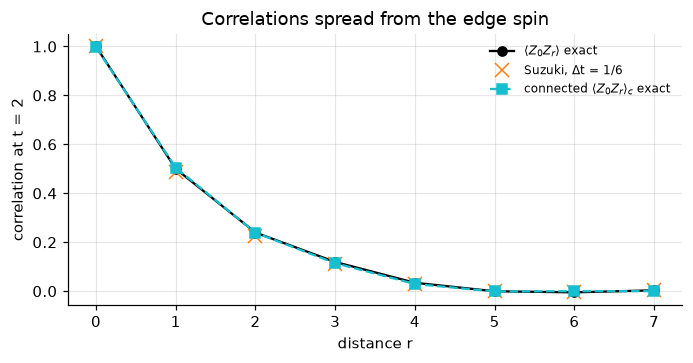

r      : [0, 1, 2, 3, 4, 5, 6, 7]
<Z0Zr> : [ 1.000e+00  5.001e-01  2.396e-01  1.193e-01  3.420e-02 -4.000e-04
 -4.800e-03  3.400e-03]
conn.  : [ 9.966e-01  5.048e-01  2.388e-01  1.143e-01  2.920e-02 -1.200e-03
 -2.000e-04  0.000e+00]


In [6]:
psi_T = exact_state(T_FINAL)
zz = np.array([engine.zz_corr(psi_T, 0, r) for r in range(N)])
z_site = np.array([float(np.sum(np.abs(psi_T)**2 * engine.z[:, i])) for i in range(N)])   # <Z_i>
conn = zz - z_site[0] * z_site
psi_T_suz = engine.trajectory(T_FINAL / 12, 12, "suzuki")[-1]
zz_suz = np.array([engine.zz_corr(psi_T_suz, 0, r) for r in range(N)])

fig, ax = plt.subplots(figsize=(6.4, 3.4))
ax.plot(range(N), zz, "o-", color=COL["exact"], label=r"$\langle Z_0Z_r\rangle$ exact")
ax.plot(range(N), zz_suz, "x", ms=9, color=COL["suzuki"], label=r"Suzuki, Δt = 1/6")
ax.plot(range(N), conn, "s--", color="#17becf", label=r"connected $\langle Z_0Z_r\rangle_c$ exact")
ax.set_xlabel("distance r"); ax.set_ylabel("correlation at t = 2"); ax.legend(fontsize=8)
ax.set_title("Correlations spread from the edge spin"); plt.tight_layout(); savefig("b2_correlations"); plt.show()
print("r      :", list(range(N)))
print("<Z0Zr> :", np.round(zz, 4))
print("conn.  :", np.round(conn, 4))

### 1.3 The largest step that keeps the error below 0.01 over the whole run

For $\Delta t = 2/n$, $n=1,2,\dots$, we compare $M_z$ and $M_x$ with the exact values at **every** step time $k\Delta t$ ($k=0..n$) and record the worst error. "Largest $\Delta t$" means the smallest $n$ whose run stays below 0.01. We also checked that every finer step stays below the threshold. We include a third ordering, field terms first ("Strang"), because it changes the answer.

In [7]:
# For 8 spins every factor is a 256x256 matrix, so a Trotter step is a single matrix product.
Hzz_m = SparsePauliOp.from_list([(l, c) for l, c in H.to_list() if "X" not in l]).to_matrix()
Hx_m = Hm - Hzz_m
zbar = engine.z.mean(axis=1)                                   # diagonal of M_z

def step_matrix(dt, scheme):
    Uzz = lambda tau: np.diag(np.exp(-1j * tau * np.diag(Hzz_m)))
    Ux = lambda tau: expm(-1j * tau * Hx_m)
    return {"lie": Ux(dt) @ Uzz(dt),                           # matrix order: rightmost acts first
            "suzuki": Uzz(dt / 2) @ Ux(dt) @ Uzz(dt / 2),
            "strang": Ux(dt / 2) @ Uzz(dt) @ Ux(dt / 2)}[scheme]

def worst_errors(n, scheme, T=2.0):
    dt = T / n
    U, Uex = step_matrix(dt, scheme), expm(-1j * Hm * dt)
    a, b = psi0.copy(), psi0.copy()
    ez = ex = 0.0
    for _ in range(n):
        a, b = U @ a, Uex @ b
        ez = max(ez, abs(np.sum((np.abs(a)**2 - np.abs(b)**2) * zbar)))
        ex = max(ex, abs(np.real(np.vdot(a, Mx_m @ a) - np.vdot(b, Mx_m @ b))))
    return ez, ex

N_LIST = list(range(1, 61)) + list(range(65, 205, 5))
t0 = time.time()
scan8 = {s: np.array([(n, 2.0 / n, *worst_errors(n, s)) for n in N_LIST]) for s in ("lie", "suzuki", "strang")}
print(f"scanned {3*len(N_LIST)} step sizes in {time.time()-t0:.1f}s")

def threshold(rows, col, scheme, tol=0.01):
    ok = rows[:, col] < tol
    for i in range(len(rows)):                      # first scanned n after which it stays below tol
        if ok[i:].all():
            break
    lo = int(rows[i - 1, 0]) if i > 0 else 0        # refine every n between the coarse grid points
    for n in range(lo + 1, int(rows[i, 0]) + 1):
        e = worst_errors(n, scheme)[col - 2]
        if e < tol:
            return n, 2.0 / n, e
    return int(rows[i, 0]), rows[i, 1], rows[i, col]

# two-qubit gate cost of a full run to t=2, as Qiskit builds it, and with our merged circuits
def cx_qiskit(n_steps, dt, scheme):
    HH = il.tfim_hamiltonian(N, J, h, x_first=(scheme == "strang"))
    return qiskit_trotter_circuit(HH, n_steps, dt, 1 if scheme == "lie" else 2).num_nonlocal_gates()
def cx_merged(n_steps, dt, scheme, keep_final_zz=True):
    qc = il.tfim_trotter_circuit(N, dt, n_steps, scheme)
    return 2 * qc.num_nonlocal_gates()           # each RZZ = 2 CX/CZ on hardware without fractional gates

table = []
for s in ("lie", "suzuki", "strang"):
    for col, obs in ((2, "Mz"), (3, "Mx")):
        n_, dt_, err_ = threshold(scan8[s], col, s)
        table.append((s, obs, n_, dt_, err_, cx_qiskit(n_, dt_, s), cx_qiskit(n_, dt_, s) // n_, cx_merged(n_, dt_, s)))
print(f"{'formula':8s} {'obs':3s} {'steps':>5s} {'largest dt':>10s} {'max err':>8s} {'CX (Qiskit)':>11s} {'CX/step':>7s} {'CX (merged)':>11s}")
for r in table:
    print(f"{r[0]:8s} {r[1]:3s} {r[2]:5d} {r[3]:10.4f} {r[4]:8.4f} {r[5]:11d} {r[6]:7d} {r[7]:11d}")
json.dump([dict(zip(["formula", "obs", "steps", "dt", "err", "cx_qiskit", "cx_per_step", "cx_merged"],
                    [r[0], r[1], int(r[2]), float(r[3]), float(r[4]), int(r[5]), int(r[6]), int(r[7])])) for r in table],
          open(RESULTS / "beginner_thresholds.json", "w"), indent=1)

scanned 264 step sizes in 53.3s


formula  obs steps largest dt  max err CX (Qiskit) CX/step CX (merged)
lie      Mz     12     0.1667   0.0098         168      14         154
lie      Mx    132     0.0152   0.0099        1848      14        1834
suzuki   Mz     12     0.1667   0.0098         336      28         168
suzuki   Mx     11     0.1818   0.0089         308      28         154
strang   Mz     17     0.1176   0.0099         442      26         238
strang   Mx      9     0.2222   0.0084         234      26         126


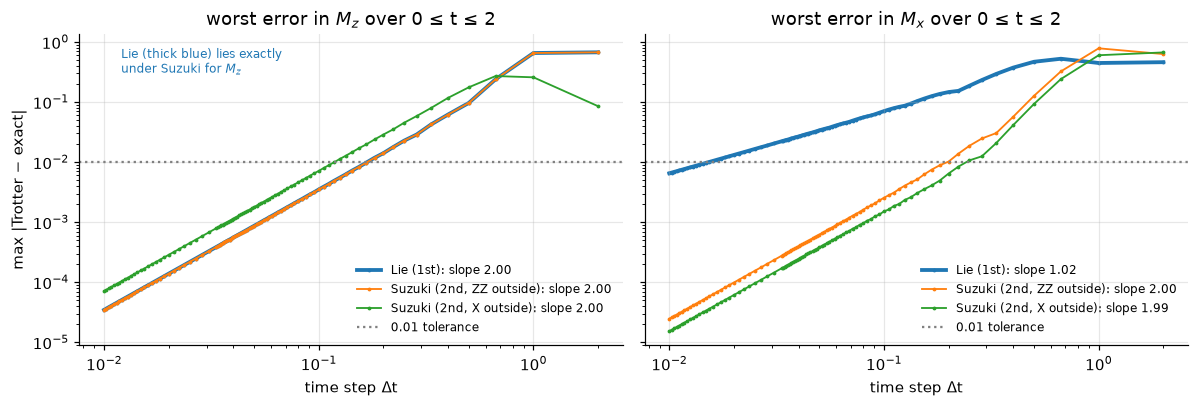

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, col, obs in ((axes[0], 2, "M_z"), (axes[1], 3, "M_x")):
    for s, lab in (("lie", "Lie (1st)"), ("suzuki", "Suzuki (2nd, ZZ outside)"), ("strang", "Suzuki (2nd, X outside)")):
        rows = scan8[s]
        m = rows[:, 1] < 0.08                       # fit the convergence order on the small-dt tail
        p = np.polyfit(np.log(rows[m, 1]), np.log(rows[m, col]), 1)[0]
        ax.loglog(rows[:, 1], rows[:, col], ".-", ms=3, color=COL[s], label=f"{lab}: slope {p:.2f}",
                  lw=2.5 if s == "lie" else 1.2, zorder=1 if s == "lie" else 2)
    ax.axhline(0.01, color="grey", ls=":", label="0.01 tolerance")
    ax.set_xlabel("time step Δt"); ax.set_title(f"worst error in ${obs}$ over 0 ≤ t ≤ 2")
axes[0].set_ylabel("max |Trotter − exact|")
for ax in axes: ax.legend(fontsize=8, loc="lower right")
axes[0].text(0.012, 0.3, "Lie (thick blue) lies exactly\nunder Suzuki for $M_z$", fontsize=8, color=COL["lie"])
plt.tight_layout(); savefig("b3_dt_scan"); plt.show()

### 1.4 Which formula is cheaper, and why the answer depends on what you measure

Read the gate sequences in time order, starting from $|0\cdots0\rangle$:

* Lie: $\;ZZ(\Delta t)\,X\,ZZ\,X\cdots ZZ\,X$
* Suzuki: $\;ZZ(\tfrac{\Delta t}{2})\,X\,ZZ(\Delta t)\,X\cdots X\,ZZ(\tfrac{\Delta t}{2})$

Two boundary facts decide everything:

1. **The first ZZ layer does nothing.** $|0\cdots0\rangle$ is an eigenstate of every $Z_iZ_{i+1}$, so that layer only adds a global phase.
2. **A final ZZ layer cannot change any Z-basis observable**, since it commutes with $Z_i$ and $Z_iZ_j$.

Strip those two pieces and **Lie and Suzuki apply exactly the same operator sequence for $M_z$ and $\langle Z_0Z_r\rangle$**. So Lie-Trotter is effectively second order for Z observables: the fitted slope is 2, not 1. For $M_x$ the final half-step $ZZ(\Delta t/2)$ *does* matter. It is precisely the correction that cancels the leading error term, so Lie stays first order (slope 1) and needs a ~10× smaller step. Ordering the field terms first ("Strang") moves the half-steps onto the X layers, which flips the roles: $M_x$ becomes the easy observable and $M_z$ the hard one.

**Cost.** Qiskit's `SuzukiTrotter` emits two ZZ half-layers per step, so it costs 2× the CX gates of Lie per step (column "CX/step"). Neighbouring half-steps of consecutive Suzuki steps merge, though. Our `tfim_trotter_circuit` merges them and drops the trivial first layer, so a 2nd-order run costs the **same CX count as a 1st-order run** (column "CX (merged)"). The cheapest correct choice:

* Z-only observables: Lie-Trotter (identical to Suzuki here, with fewer gates).
* $M_x$, or both observables at once: merged Suzuki-Trotter with $\Delta t = 2/13$, about 13× fewer CX gates than Lie at $\Delta t = 2/132$.

In [9]:
# the claim "Lie == Suzuki for every Z-basis observable" holds to machine precision:
for dt, k in ((0.5, 4), (0.2, 10), (0.1, 20)):
    a = engine.trajectory(dt, k, "lie"); b = engine.trajectory(dt, k, "suzuki")
    dz = max(abs(engine.mz(x) - engine.mz(y)) for x, y in zip(a, b))
    dzz = max(abs(engine.zz_corr(x, 0, 5) - engine.zz_corr(y, 0, 5)) for x, y in zip(a, b))
    dx = max(abs(engine.mx(x) - engine.mx(y)) for x, y in zip(a, b))
    print(f"dt={dt}:  max|ΔMz| = {dz:.1e}   max|Δ<Z0Z5>| = {dzz:.1e}   but max|ΔMx| = {dx:.3f}")

dt=0.5:  max|ΔMz| = 4.4e-16   max|Δ<Z0Z5>| = 6.9e-17   but max|ΔMx| = 0.341
dt=0.2:  max|ΔMz| = 2.4e-16   max|Δ<Z0Z5>| = 2.2e-16   but max|ΔMx| = 0.137
dt=0.1:  max|ΔMz| = 6.7e-16   max|Δ<Z0Z5>| = 6.7e-16   but max|ΔMx| = 0.069


## 2 · 🟠 Intermediate: recovering the physics that noise hides (12 spins)

Same model, now with $N=12$ spins, $J=h=1$, $0\le t\le 2$, and realistic noise. The plan follows what a hardware run actually needs:

1. **Cut the circuit first** (§2.1). Every CZ we remove is error we never have to mitigate.
2. **Model the noise** from FakeFez (IBM Heron r2, 156 qubits) calibration data (§2.2).
3. **Mitigate**, one rung at a time, with code we wrote ourselves (§2.3): readout twirling (TREX), Pauli twirling, and zero-noise extrapolation (ZNE) by CZ folding.
4. **Choose the Trotter step under noise** (§2.4). A finer step lowers Trotter error but adds CZ errors, so the optimum is a trade-off.
5. **Run the same circuit on a real IBM QPU** and compare (§2.5).

We use merged 2nd-order Suzuki-Trotter with $\Delta t = 0.25$ (8 steps to $t=2$). For 12 spins its Trotter error is 0.024 in $M_z$ and 0.018 in $M_x$. §2.4 shows why we pick this step and not the finer $\Delta t \approx 0.15$ that the 0.01 tolerance would need.

In [10]:
from qiskit.transpiler import generate_preset_pass_manager
from qiskit_ibm_runtime.fake_provider import FakeFez

N12, DT12, STEPS12 = 12, 0.25, list(range(1, 9))
fez = FakeFez()
t12 = np.array([0] + [s * DT12 for s in STEPS12])

# exact reference (dense, 4096-dim) and the noiseless Trotter circuit the hardware will run
eng12 = il.TFIMEngine(N12)
H12 = il.tfim_hamiltonian(N12).to_matrix()
w12, V12 = np.linalg.eigh(H12); c12 = V12.conj().T[:, 0]
exact12 = [V12 @ (np.exp(-1j * w12 * t) * c12) for t in t12]
mz12_exact = np.array([eng12.mz(p) for p in exact12]); mx12_exact = np.array([eng12.mx(p) for p in exact12])
tro12 = eng12.trajectory(DT12, STEPS12[-1], "suzuki")
mz12_trot = np.array([eng12.mz(p) for p in tro12]); mx12_trot = np.array([eng12.mx(p) for p in tro12])
print("Trotter error of the noiseless circuit:  Mz %.4f   Mx %.4f" %
      (np.abs(mz12_trot - mz12_exact).max(), np.abs(mx12_trot - mx12_exact).max()))

Trotter error of the noiseless circuit:  Mz 0.0243   Mx 0.0183


### 2.1 Cutting depth before mitigating: circuit structure and layout

Four ways to compile the same $t=2$ evolution for FakeFez. We score each by **CZ count**, **two-qubit depth**, **SWAPs added by routing**, and the **estimated success probability** $\text{ESP}=\prod_{\text{gates}}(1-\epsilon_g)\prod_{\text{measured qubits}}(1-\epsilon_{\text{ro}})$, computed from FakeFez's calibration. ESP is the standard first-order figure of merit for comparing compiled circuits.

* **(a) Qiskit `SuzukiTrotter`, default layout.** `PauliEvolutionGate`, transpiled at optimisation level 2.
* **(b) Our merged brickwork circuit, default layout.** Half-steps merged, trivial first layer dropped. Even bonds, then odd bonds, so the two-qubit depth per step is 2·2 = 4 CZ layers whatever N is.
* **(c) Our circuit on an error-aware line.** `il.best_line` runs a beam search over the heavy-hex coupling map for the 12-qubit path with the lowest summed CZ, readout and SX infidelity.
* **(d) Our circuit on a careless layout.** 12 scattered qubits, so the router has to insert SWAPs.

In [11]:
def esp(isa, backend, n_meas):
    t = backend.target
    logf = 0.0
    for inst in isa.data:
        name = inst.operation.name
        if name in ("barrier", "measure", "delay") or name not in t.operation_names:
            continue
        qs = tuple(isa.find_bit(q).index for q in inst.qubits)
        props = t[name].get(qs)
        if props is not None and props.error is not None:
            logf += math.log(max(1e-12, 1 - props.error))
    phys = list(isa.layout.final_index_layout(filter_ancillas=True))[:n_meas]
    for q in phys:
        logf += math.log(1 - (t["measure"][(q,)].error or 0))
    return math.exp(logf)

def summarize(label, isa, cz_perfect):
    # the transpiler decomposes SWAPs into 3 CZs, so routing overhead = extra CZs / 3
    cz = int(isa.count_ops().get("cz", 0))
    return (label, cz, int(isa.depth(lambda i: i.operation.num_qubits == 2)),
            round((cz - cz_perfect) / 3), esp(isa, fez, N12))

steps_T = STEPS12[-1]
qiskit_circ = qiskit_trotter_circuit(il.tfim_hamiltonian(N12), steps_T, DT12, order=2)
ours = il.tfim_trotter_circuit(N12, DT12, steps_T, "suzuki")
# line cost = -log(ESP) of this circuit: 16 CZ per bond, ~30 SX per qubit
line12, line12_cost = il.best_line(fez.target, N12, cz_per_bond=16, sx_per_qubit=30)
rng = np.random.default_rng(3)
scattered = [int(q) for q in rng.choice(fez.num_qubits, N12, replace=False)]

pm_default = generate_preset_pass_manager(optimization_level=2, backend=fez, seed_transpiler=1)
pm_line = generate_preset_pass_manager(optimization_level=2, backend=fez, initial_layout=line12)
pm_bad = generate_preset_pass_manager(optimization_level=2, backend=fez, initial_layout=scattered, seed_transpiler=1)
cz_q = int(pm_line.run(qiskit_circ).count_ops().get("cz", 0))      # CZ count with no routing at all
cz_o = int(pm_line.run(ours).count_ops().get("cz", 0))
rows21 = [summarize("(a) Qiskit SuzukiTrotter, default layout", pm_default.run(qiskit_circ), cz_q),
          summarize("(b) merged brickwork, default layout", pm_default.run(ours), cz_o),
          summarize("(c) merged brickwork, error-aware line", pm_line.run(ours), cz_o),
          summarize("(d) merged brickwork, scattered qubits", pm_bad.run(ours), cz_o)]
print(f"{'circuit':44s} {'CZ':>5s} {'2q depth':>8s} {'SWAPs':>5s} {'ESP':>7s}")
for r in rows21:
    print(f"{r[0]:44s} {r[1]:5d} {r[2]:8d} {r[3]:5d} {r[4]:7.3f}")
print("\nerror-aware line on FakeFez:", line12)

circuit                                         CZ 2q depth SWAPs     ESP
(a) Qiskit SuzukiTrotter, default layout       322      322     0   0.298
(b) merged brickwork, default layout           176       32     0   0.499
(c) merged brickwork, error-aware line         176       32     0   0.499
(d) merged brickwork, scattered qubits         747      184   190   0.000

error-aware line on FakeFez: [147, 137, 127, 126, 125, 124, 123, 136, 143, 142, 141, 140]


**What the table says.** Merging and brickwork ordering (a → b) roughly halve the CZ count and the two-qubit depth. The scattered layout (d) shows what routing costs: the router's SWAPs (3 CZ each, counted as extra CZs because the transpiler decomposes them) multiply the gate count and ESP collapses. The VF2 layout pass in Qiskit's default compilation already finds a perfect line for a 12-qubit chain, so (b) and (c) are close here. Our line search optimises the same −log ESP directly (weights = 16 CZ per bond, ~30 SX per qubit). For the 100-qubit chain in §3 a default layout is no longer reliable, which is why we search for the line ourselves using calibration data.

### 2.2 The noise model, and a check that it is faithful

Simulating the full 156-qubit FakeFez noise model costs ~40 s per circuit, which is too slow for hundreds of mitigation circuits. So we build a **compact noise model** (`il.compact_noise_model`) for just the 12 chosen qubits, from FakeFez's calibration data:
* depolarising CZ, SX and X errors whose strength matches each gate's reported average error ($\lambda = r\,d/(d-1)$);
* each qubit's own **asymmetric** readout error.

Pauli twirling turns hardware noise into this kind of Pauli channel anyway. Below we compare it with the complete `AerSimulator.from_backend(FakeFez())` model, which adds thermal relaxation, on the raw $M_z$ at three depths.

In [12]:
if RECOMPUTE:
    import subprocess, sys
    subprocess.run([sys.executable, "scripts/intermediate_sim.py"], check=True)   # ~10-15 min

sim12 = dict(np.load(RESULTS / "intermediate_sim.npz"))
tradeoff = json.load(open(RESULTS / "tradeoff_sim.json"))
model_check = json.load(open(RESULTS / "noise_model_check.json")) if (RESULTS / "noise_model_check.json").exists() else []
print("simulated line:", sim12["path"].tolist())
print(f"{'t':>5s} {'full FakeFez model':>19s} {'compact model':>14s}   (raw M_z, 1000 / 4000 shots)")
for r in model_check:
    print(f"{r['t']:5.2f} {r['full_fakefez_mz']:19.4f} {r['compact_mz']:14.4f}")

simulated line: [147, 137, 127, 126, 125, 124, 123, 136, 143, 142, 141, 140]
    t  full FakeFez model  compact model   (raw M_z, 1000 / 4000 shots)
 0.50              0.6082         0.6060
 1.00              0.2538         0.2325
 2.00              0.0247         0.0372


### 2.3 Error mitigation, one rung at a time

Each rung is implemented in `ising_lab.py`:

| Rung | What it does | Why it works |
|---|---|---|
| raw | measure, average $\langle Z_i\rangle$ or $\langle X_i\rangle$ (X basis via $H=R_Z S_X R_Z$) | — |
| **TREX** | random X before each readout, undone classically (K = 8 masks); divide by the same twirled readout of $\lvert0\cdots0\rangle$ | twirling makes readout noise a pure scale factor $f_i$, which the calibration measures |
| **Pauli twirling** | random Paulis around every CZ, cancelled after it | turns coherent CZ errors into stochastic Pauli noise that ZNE can extrapolate |
| **ZNE** | fold every CZ into CZ·CZ·CZ (λ=3) or 5 CZs (λ=5); extrapolate λ→0 (linear, exponential, Richardson) | for Pauli noise, ⟨O⟩(λ) decays smoothly with λ |

One honest observation. In a Pauli noise model, twirling the CZ gates changes nothing on average, because the channel is already Pauli-symmetric. We verify that once below. Twirling earns its keep on real hardware, where coherent errors (ZZ crosstalk, miscalibrated phases) are present. There we let IBM's Estimator twirl, together with dynamical decoupling, which suppresses errors on idle qubits.

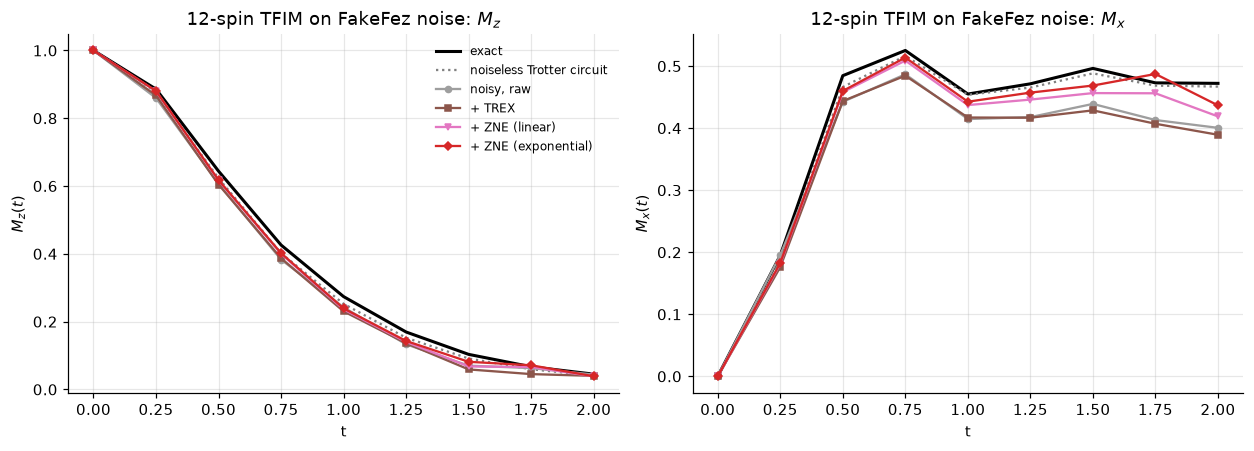

rung                     mean|err| vs noiseless circuit   mean|err| vs exact
Mz  raw                                          0.0137               0.0265
Mz  trex                                         0.0162               0.0306
Mz  zne_lin                                      0.0089               0.0212
Mz  zne_exp                                      0.0069               0.0187
Mz  zne_rich                                     0.0246               0.0223
Mx  raw                                          0.0402               0.0455
Mx  trex                                         0.0435               0.0512
Mx  zne_lin                                      0.0185               0.0262
Mx  zne_exp                                      0.0125               0.0191
Mx  zne_rich                                     0.0129               0.0176

readout calibration factors f_i: [0.98  0.991 0.953 0.996 0.976 0.987 0.98  0.99  0.991 0.993 0.993 0.987]
Pauli-twirling check at t=2 (Pauli noise):  T

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))
lad_err = {}
for ax, basis, ex, tr, name in ((axes[0], "Z", mz12_exact, mz12_trot, "M_z"), (axes[1], "X", mx12_exact, mx12_trot, "M_x")):
    ax.plot(t12, ex, color=COL["exact"], lw=2, label="exact")
    ax.plot(t12, tr, ":", color="grey", lw=1.5, label="noiseless Trotter circuit")
    for key, lab, c, mk in (("raw", "noisy, raw", COL["raw"], "o"), ("trex", "+ TREX", COL["trex"], "s"),
                            ("zne_lin", "+ ZNE (linear)", "#e377c2", "v"), ("zne_exp", "+ ZNE (exponential)", COL["zne"], "D")):
        y = np.concatenate([[1.0 if basis == "Z" else 0.0], sim12[f"{basis}_{key}"].mean(axis=1)])
        ax.plot(t12, y, mk + "-", ms=4, color=c, label=lab)
        lad_err[(basis, key)] = (np.abs(y[1:] - tr[1:]).mean(), np.abs(y[1:] - ex[1:]).mean())
    ax.set_xlabel("t"); ax.set_ylabel(f"${name}(t)$"); ax.set_title(f"12-spin TFIM on FakeFez noise: ${name}$")
axes[0].legend(fontsize=8)
plt.tight_layout(); savefig("i1_mitigation_ladder"); plt.show()

print(f"{'rung':22s} {'mean|err| vs noiseless circuit':>32s} {'mean|err| vs exact':>20s}")
for basis in ("Z", "X"):
    for key in ("raw", "trex", "zne_lin", "zne_exp", "zne_rich"):
        if (basis, key) not in lad_err:
            y = sim12[f"{basis}_{key}"].mean(axis=1)
            tr, ex = (mz12_trot, mz12_exact) if basis == "Z" else (mx12_trot, mx12_exact)
            lad_err[(basis, key)] = (np.abs(y - tr[1:]).mean(), np.abs(y - ex[1:]).mean())
        a, b = lad_err[(basis, key)]
        print(f"M{basis.lower()}  {key:18s} {a:32.4f} {b:20.4f}")
print("\nreadout calibration factors f_i:", np.round(sim12["Z_cal"], 3))
print("Pauli-twirling check at t=2 (Pauli noise):  TREX only %.4f   TREX + twirled CZs %.4f"
      % (sim12["twirl_demo_trex"].mean(), sim12["twirl_demo_twirl"].mean()))

### 2.4 Choosing the Trotter step when the hardware is noisy

The Beginner analysis asked for the step that keeps *Trotter* error below 0.01. On a noisy device that is the wrong target. The total error is roughly

$$\varepsilon_{\text{total}}(\Delta t) \approx \underbrace{c\,\Delta t^2}_{\text{Trotter}} + \underbrace{1-e^{-\gamma\,n_{CZ}(\Delta t)}}_{\text{noise},\ n_{CZ}\propto 1/\Delta t},$$

so there is an optimal $\Delta t$. Below we sweep $\Delta t = 2/n$ at the final time $t=2$: noiseless Trotter error, raw noisy error, and ZNE-mitigated error.

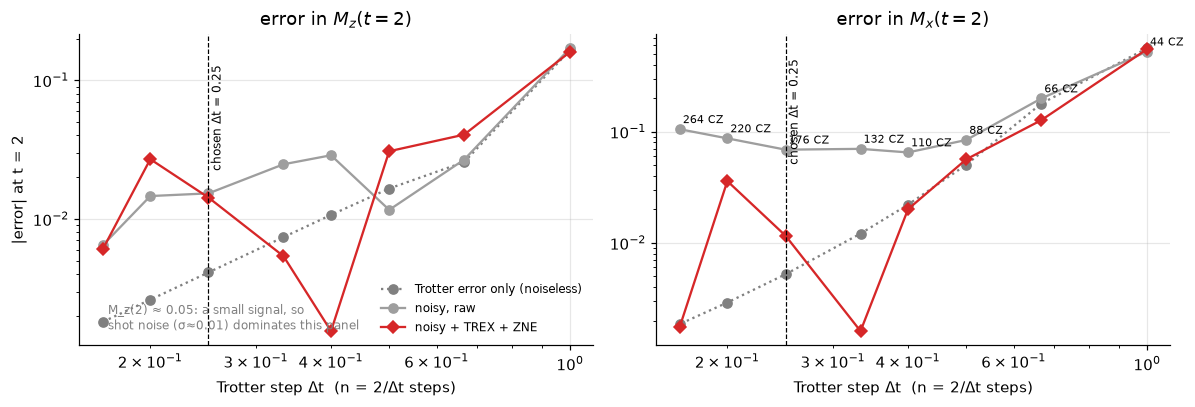

In [14]:
def exact_at(t):
    return V12 @ (np.exp(-1j * w12 * t) * c12)
ex2 = exact_at(2.0); mz_ex2, mx_ex2 = eng12.mz(ex2), eng12.mx(ex2)
ns = np.array([r["ns"] for r in tradeoff]); dts = 2 / ns
trot_err = []
for n_ in ns:
    psi = eng12.trajectory(2 / n_, int(n_), "suzuki")[-1]
    trot_err.append((abs(eng12.mz(psi) - mz_ex2), abs(eng12.mx(psi) - mx_ex2)))
trot_err = np.array(trot_err)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharex=True)
for ax, b, j, exv, name in ((axes[0], "Z", 0, mz_ex2, "M_z"), (axes[1], "X", 1, mx_ex2, "M_x")):
    ax.plot(dts, trot_err[:, j], "o:", color="grey", label="Trotter error only (noiseless)")
    ax.plot(dts, [abs(r[f"{b}_raw"] - exv) for r in tradeoff], "o-", color=COL["raw"], label="noisy, raw")
    ax.plot(dts, [abs(r[f"{b}_zne_exp"] - exv) for r in tradeoff], "D-", color=COL["zne"], label="noisy + TREX + ZNE")
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("Trotter step Δt  (n = 2/Δt steps)")
    ax.set_title(f"error in ${name}(t=2)$"); ax.axvline(0.25, color="k", lw=0.8, ls="--")
axes[0].set_ylabel("|error| at t = 2"); axes[0].legend(fontsize=8)
axes[0].text(0.17, 0.0016, "M_z(2) ≈ 0.05: a small signal, so\nshot noise (σ≈0.01) dominates this panel", fontsize=8, color="grey")
for ax in axes: ax.text(0.252, ax.get_ylim()[1] * 0.6, "chosen Δt = 0.25", fontsize=8, rotation=90, va="top")
for r in tradeoff:
    axes[1].annotate(f"{r['cz']} CZ", (r["dt"], abs(r["X_raw"] - mx_ex2)), fontsize=7, xytext=(2, 4), textcoords="offset points")
plt.tight_layout(); savefig("i2_tradeoff"); plt.show()

The $M_x$ panel is the informative one. On FakeFez-level noise the raw error is set by noise, not Trotter error, for $\Delta t \lesssim 0.4$. The ZNE-mitigated error reaches its minimum at $\Delta t = 0.25$ (176 CZ), where it meets the noiseless Trotter-error curve. The $M_z(2)$ signal is only about 0.05, so that panel is dominated by shot noise and we do not draw conclusions from it. Going finer adds CZ layers faster than it removes Trotter error. This is why our hardware runs use $\Delta t = 0.25$: the **total** error is what matters, and the Trotter-error-only criterion from the Beginner level would add ~60% more CZ gates for no net gain.

### 2.5 The same 12-spin circuit on a real IBM QPU

Job B runs these eight circuits on hardware through IBM's `EstimatorV2`, with TREX, Pauli-twirled CZs, XpXm dynamical decoupling and gate-folding ZNE ($\lambda = 1, 3, 5$). We plot the device result at $\lambda=1$ (twirled, readout-mitigated, before extrapolation) and after ZNE, against our noisy simulation and the exact curve.

In [15]:
hwB_path = RESULTS / "hardware_B.npz"
jobs_meta = json.load(open(RESULTS / "hardware_jobs.json")) if (RESULTS / "hardware_jobs.json").exists() else None

def hw_noise_factor_slice(d, i, which=0):
    # EstimatorV2 with ZNE returns evs (extrapolated) and evs_noise_factors (..., n_factors)
    for key in (f"p{i}_evs_noise_factors",):
        if key in d:
            return np.asarray(d[key])[..., which]
    return None

if hwB_path.exists():
    dB = dict(np.load(hwB_path))
    hz, hx, hz1, hx1 = [], [], [], []
    for i in range(len(STEPS12)):
        ev = dB[f"p{i}_evs"]; hz.append(ev[:N12].mean()); hx.append(ev[N12:].mean())
        nf = hw_noise_factor_slice(dB, i)
        if nf is not None:
            hz1.append(nf[:N12].mean()); hx1.append(nf[N12:].mean())
    fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.0))
    for ax, ex, sraw, szne, hwz, hw1, name in ((axes[0], mz12_exact, sim12["Z_raw"], sim12["Z_zne_exp"], hz, hz1, "M_z"),
                                              (axes[1], mx12_exact, sim12["X_raw"], sim12["X_zne_exp"], hx, hx1, "M_x")):
        ax.plot(t12, ex, color=COL["exact"], lw=2, label="exact")
        ax.plot(t12[1:], sraw.mean(1), "o--", color=COL["raw"], ms=4, label="FakeFez sim, raw")
        ax.plot(t12[1:], szne.mean(1), "D--", color="#ff9896", ms=4, label="FakeFez sim, TREX+ZNE")
        if hw1:
            ax.plot(t12[1:], hw1, "s-", color="#1f77b4", ms=5, label=f"{jobs_meta['backend']}: λ=1 (TREX+twirl+DD)")
        ax.plot(t12[1:], hwz, "D-", color=COL["hw"], ms=5, label=f"{jobs_meta['backend']}: + ZNE")
        ax.set_xlabel("t"); ax.set_ylabel(f"${name}$"); ax.set_title(f"12 spins on real hardware: ${name}$")
    axes[0].legend(fontsize=7.5)
    plt.tight_layout(); savefig("i3_hardware_tfim"); plt.show()
    print("mean |QPU+ZNE - exact|:  Mz %.4f   Mx %.4f" % (np.abs(np.array(hz) - mz12_exact[1:]).mean(),
                                                         np.abs(np.array(hx) - mx12_exact[1:]).mean()))
else:
    print("results/hardware_B.npz not found: run hardware/run_hardware.py submit / fetch to add the QPU curve.")

results/hardware_B.npz not found: run hardware/run_hardware.py submit / fetch to add the QPU curve.


## 3 · 🔴 Advanced: a 100-qubit kicked-Ising chain on IBM hardware, certified without brute force

**Model** (as in Kim *et al.*, Nature 618, 500 (2023), on a 1D chain). One Floquet step is

$$U_F(\theta_h) = \prod_j R_X^{(j)}(\theta_h)\;\prod_{\langle j,k\rangle} R_{ZZ}^{(jk)}(\theta_J),\qquad \theta_J=-\pi/2,$$

applied $t$ times to $|0\rangle^{\otimes N}$ on an open chain of **N = 100** qubits. We measure every $\langle Z_i\rangle$ (magnetisation $M_z$) and every nearest-neighbour $\langle Z_iZ_{i+1}\rangle$, for $\theta_h\in\{0,\pi/8,\pi/4,3\pi/8\}$ and $t\in\{1,\dots,8,10,12,14,16,20\}$. That is 52 circuits with up to **1881 CZ gates** at two-qubit depth 38.

**Why this circuit suits the hardware.** At $\theta_J=-\pi/2$ each $R_{ZZ}$ is exactly **one CZ** plus single-qubit phases. On a 1D line of physically coupled qubits, routing needs **zero SWAPs**. And on $|0\cdots0\rangle$ the first ZZ layer is only a global phase, so we delete it.

### 3.1 How do we know the answer when $2^{100}$ amplitudes are out of reach?

The challenge asks us to argue correctness without brute force. We built **three independent exact methods**. Each one scales to 100 qubits, and each is cross-checked against the others and against statevector simulation:

| Method | Gives | Cost | Valid for |
|---|---|---|---|
| **Light-cone window** (`il.kicked_ising_exact_profile`) | every $\langle Z_i\rangle$, $\langle Z_iZ_{i+1}\rangle$ | statevector on $2t+2$ qubits, independent of N | any model with local gates, up to $t\approx 11$ |
| **Free fermions + Pfaffians** (`il.free_fermion_profile`) | every $\langle Z_i\rangle$ and *any* $\langle Z_iZ_j\rangle$ | $O(N^3)$, about 3 s for N = 100 | the integrable 1D kicked transverse-field Ising chain, **any depth** |
| **Clifford point** $\theta_h=\pi/2$ (`il.clifford_stabilizer`) | evolved stabilisers $S=UZ_cU^\dagger$, $\langle S\rangle=+1$ | stabiliser tableau, polynomial | any N, any depth |

The free-fermion trick. With a Jordan-Wigner transformation in the X basis, $X_j=-i\gamma_{2j}\gamma_{2j+1}$ and $Z_jZ_{j+1}=-i\gamma_{2j+1}\gamma_{2j+2}$. Every gate is then a rotation of the Majorana vector, and the covariance matrix evolves as $M\to RMR^T$. $|0\cdots0\rangle=(|\text{GHZ}_+\rangle+|\text{GHZ}_-\rangle)/\sqrt2$ is a sum of two Gaussian states, and the two parity sectors do not interfere for parity-even observables. $Z_i$ itself is parity-odd: it is a non-local string. So we add a **ghost spin** that never evolves, which gives $\langle Z_i\rangle = \langle Z_gZ_i\rangle$, an even Majorana product. Wick's theorem then evaluates it as a **Pfaffian**.

One caveat we state openly: integrability is what lets us certify 100 qubits at depth 20. It also means this particular model is classically easy. We use it as a calibrated benchmark of the hardware plus mitigation stack, not as a claim of quantum advantage.

In [16]:
_jm = json.load(open(RESULTS / "hardware_jobs.json")) if (RESULTS / "hardware_jobs.json").exists() else None
N_KI = _jm["plan"]["N_KI"] if _jm else 100          # chain length actually run on the QPU
TH = {"0": 0.0, "π/8": np.pi / 8, "π/4": np.pi / 4, "3π/8": 3 * np.pi / 8}
T_KI = [1, 2, 3, 4, 5, 6, 7, 8, 10, 12, 14, 16, 20]

# (1) all three exact methods vs full statevector on a 12-qubit chain
n_small, worst = 12, 0.0
for t in (1, 3, 5):
    for th in TH.values():
        sv = Statevector(il.kicked_ising_circuit(n_small, t, th))
        z_sv = np.array([np.real(sv.expectation_value(o)) for o in il.single_site_ops(n_small)])
        z_ff, _ = il.free_fermion_profile(n_small, t, th)
        z_lc, _ = il.kicked_ising_exact_profile(n_small, t, [th])
        worst = max(worst, np.abs(z_ff - z_sv).max(), np.abs(z_lc[0] - z_sv).max())
    S = il.clifford_stabilizer(n_small, t, n_small // 2)
    print(f"t={t}: Clifford stabiliser weight {sum(c != 'I' for c in S.paulis[0].to_label()):2d}, "
          f"<S> statevector = {np.real(Statevector(il.kicked_ising_circuit(n_small, t, np.pi/2)).expectation_value(S)):.12f}")
print(f"12 qubits: max |free-fermion or light-cone - statevector| = {worst:.1e}")

# (2) at N = 100: light-cone window vs free fermions (two unrelated algorithms)
t0 = time.time(); worst = 0.0
for t in (2, 5, 8):
    zlc, zzlc = il.kicked_ising_exact_profile(N_KI, t, [np.pi / 4])
    zff, zzff = il.free_fermion_profile(N_KI, t, np.pi / 4, zz_pairs=[(i, i + 1) for i in range(N_KI - 1)])
    worst = max(worst, np.abs(zlc[0] - zff).max(), np.abs(zzlc[0] - np.array([zzff[(i, i + 1)] for i in range(N_KI - 1)])).max())
print(f"N=100: max |light-cone - free-fermion| over all sites/bonds, t=2,5,8: {worst:.1e}   ({time.time()-t0:.0f}s)")

t=1: Clifford stabiliser weight  1, <S> statevector = 1.000000000000
t=3: Clifford stabiliser weight  5, <S> statevector = 1.000000000000


t=5: Clifford stabiliser weight  9, <S> statevector = 1.000000000000
12 qubits: max |free-fermion or light-cone - statevector| = 2.8e-14


N=100: max |light-cone - free-fermion| over all sites/bonds, t=2,5,8: 7.0e-15   (1s)


In [17]:
# Exact reference for every hardware circuit: site-resolved <Z_i>, <Z_i Z_i+1> and a few long-range <Z_50 Z_50+r>
LR = [1, 2, 3, 4, 6, 8, 12, 16, 24, 32, 48]
exact_ki = {}
t0 = time.time()
for lab, th in TH.items():
    for t in T_KI:
        pairs = [(i, i + 1) for i in range(N_KI - 1)] + [(N_KI // 2 - r // 2, N_KI // 2 - r // 2 + r) for r in LR]
        z, zz = il.free_fermion_profile(N_KI, t, th, zz_pairs=pairs)
        exact_ki[(lab, t)] = {"z": z, "zz": np.array([zz[(i, i + 1)] for i in range(N_KI - 1)]),
                              "lr": np.array([zz[(N_KI // 2 - r // 2, N_KI // 2 - r // 2 + r)] for r in LR])}
print(f"exact references for {len(exact_ki)} (θ_h, t) pairs at N=100 in {time.time()-t0:.0f}s")
mz_exact_ki = {lab: np.array([exact_ki[(lab, t)]["z"].mean() for t in T_KI]) for lab in TH}
for lab in TH:
    print(f"θ_h={lab:5s} exact M_z(t):", np.round(mz_exact_ki[lab], 3))

exact references for 52 (θ_h, t) pairs at N=100 in 5s
θ_h=0     exact M_z(t): [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
θ_h=π/8   exact M_z(t): [0.924 0.976 0.923 0.936 0.917 0.9   0.898 0.88  0.862 0.84  0.818 0.798
 0.763]
θ_h=π/4   exact M_z(t): [0.707 0.745 0.661 0.569 0.512 0.468 0.419 0.372 0.307 0.253 0.214 0.182
 0.141]
θ_h=3π/8  exact M_z(t): [0.383 0.269 0.182 0.117 0.076 0.051 0.037 0.029 0.022 0.019 0.018 0.017
 0.017]


### 3.2 Hardware awareness: choosing 100 qubits and compiling with zero SWAPs

`il.best_line` runs a beam search over the device's coupling map. It finds the simple path of 100 qubits with the lowest summed CZ infidelity, readout error and 2× SX error, using **that day's calibration**. A 1D chain on that path needs no routing. The submission script records the path, a calibration snapshot and the compiled-circuit statistics with every job.

**Error suppression and mitigation on the QPU** (IBM Runtime `EstimatorV2`):
* Pauli twirling of every CZ layer (16 randomisations);
* **TREX** readout mitigation;
* **XpXm dynamical decoupling** on idle windows;
* **zero-noise extrapolation** by gate folding ($\lambda = 1,3,5$), exponential extrapolation with a linear fallback.

A separate `SamplerV2` job returns **raw, unmitigated bitstrings** for two angles, plus $|0\rangle^{\otimes100}$ / $|1\rangle^{\otimes100}$ calibration shots. That gives an honest baseline and long-range correlations.

In [18]:
jobs_meta = json.load(open(RESULTS / "hardware_jobs.json")) if (RESULTS / "hardware_jobs.json").exists() else None
if jobs_meta is None:
    print("No hardware record yet: showing the compile plan on FakeFez instead.")
    import sys; sys.path.insert(0, "hardware")
    import run_hardware as rh
    (pa, ma), (pb, mb), (pc, mc), lay = rh.build_all(fez)
    meta_A, backend_name, layout = ma, "fake_fez (plan)", lay
else:
    meta_A, backend_name, layout = jobs_meta["meta"]["A"], jobs_meta["backend"], jobs_meta["layout"]
    print("backend:", backend_name, "| submitted:", jobs_meta["submitted"])
    print("job IDs:", jobs_meta["jobs"])
    cal = jobs_meta["calibration"]
    ro = np.array([v for v in cal["readout_error"].values() if v is not None])
    cz = np.array([v for v in cal["two_q_error"].values() if v is not None])
    print(f"chosen line: median CZ error {np.median(cz):.2e} (max {cz.max():.2e}), median readout error {np.median(ro):.2e} (max {ro.max():.2e})")
print("line (first 20 physical qubits):", layout["path_ki"][:20], "...")
print(f"\n{'circuit':>16s} {'CZ':>6s} {'ideal CZ':>9s} {'2q depth':>9s} {'depth':>6s} {'SWAPs':>6s}")
for m in meta_A:
    lab = f"KI t={m['t']}" if m["kind"] == "ki" else f"Clifford t={m['t']}"
    print(f"{lab:>16s} {m['two_q']:6d} {m['ideal_two_q']:9d} {m['depth_2q']:9d} {m['depth']:6d} {m['swaps']:6.0f}")
print("CZ count == (t-1)(N-1) for every circuit: the router inserted no SWAPs.")

No hardware record yet: showing the compile plan on FakeFez instead.


line (first 20 physical qubits): [124, 125, 126, 127, 128, 129, 118, 109, 110, 111, 98, 91, 90, 89, 88, 87, 86, 85, 77, 65] ...

         circuit     CZ  ideal CZ  2q depth  depth  SWAPs
          KI t=1      0         0         0      5      0
          KI t=2     99        99         2     15      0
          KI t=3    198       198         4     23      0
          KI t=4    297       297         6     31      0
          KI t=5    396       396         8     39      0
          KI t=6    495       495        10     47      0
          KI t=7    594       594        12     55      0
          KI t=8    693       693        14     63      0
         KI t=10    891       891        18     79      0
         KI t=12   1089      1089        22     95      0
         KI t=14   1287      1287        26    111      0
         KI t=16   1485      1485        30    127      0
         KI t=20   1881      1881        38    159      0
    Clifford t=2     99        99         2      9      0
 

### 3.3 Results: 100-qubit magnetisation against the exact solution

Below: raw device data (Sampler, no mitigation), the twirled and readout-mitigated estimate at $\lambda=1$, the ZNE estimate, and the exact free-fermion curve, for each $\theta_h$.

In [19]:
hwA_path, hwC_path = RESULTS / "hardware_A.npz", RESULTS / "hardware_C.npz"
HAVE_HW = hwA_path.exists()
if HAVE_HW:
    dA = dict(np.load(hwA_path))
    nki = [i for i, m in enumerate(meta_A) if m["kind"] == "ki"]
    # evs shape: (n_theta, 199) -> first 100 are Z_i, then 99 Z_i Z_i+1
    def get(i, key):
        return np.asarray(dA[f"p{i}_{key}"])
    hw = {}
    for lab_i, lab in enumerate(TH):
        hw[lab] = {"zne_z": np.array([get(i, "evs")[lab_i, :N_KI] for i in nki]),
                   "zne_zz": np.array([get(i, "evs")[lab_i, N_KI:] for i in nki]),
                   "std_z": np.array([get(i, "stds")[lab_i, :N_KI] for i in nki])}
        if f"p{nki[0]}_evs_noise_factors" in dA:
            nf = [get(i, "evs_noise_factors") for i in nki]           # (..., n_factors)
            hw[lab]["nf_z"] = np.array([x[lab_i, :N_KI, :] for x in nf])
            hw[lab]["nf_zz"] = np.array([x[lab_i, N_KI:, :] for x in nf])
    print("hardware arrays loaded:", {k: v.shape for k, v in hw["π/4"].items()})
else:
    print("results/hardware_A.npz not found yet: the plots below show only the exact reference.")

raw = {}
if hwC_path.exists():
    dC = dict(np.load(hwC_path))
    meta_C = jobs_meta["meta"]["C"]
    def unpack(i):
        bits = np.unpackbits(dC[f"p{i}_bits"], axis=-1)[:, ::-1][:, :N_KI]   # column j = clbit j = virtual qubit j
        return bits.astype(np.int8)
    i0 = [i for i, m in enumerate(meta_C) if m["kind"] == "cal0"][0]
    i1 = [i for i, m in enumerate(meta_C) if m["kind"] == "cal1"][0]
    p01 = unpack(i0).mean(0); p10 = 1 - unpack(i1).mean(0)                     # P(1|0), P(0|1) per qubit
    print(f"readout from calibration shots: mean P(1|0)={p01.mean():.3f}, mean P(0|1)={p10.mean():.3f}")
    for i, m in enumerate(meta_C):
        if m["kind"] != "raw":
            continue
        s = 1 - 2 * unpack(i)                                                   # ±1 spins
        zr = s.mean(0)
        z_ro = (zr - (p10 - p01)) / (1 - p01 - p10)                             # invert local readout channel
        lab = min(TH, key=lambda k: abs(TH[k] - m["theta"]))
        raw[(lab, m["t"])] = {"z": zr, "z_ro": z_ro, "spins": s}
    print("raw sampler circuits:", len(raw))

results/hardware_A.npz not found yet: the plots below show only the exact reference.


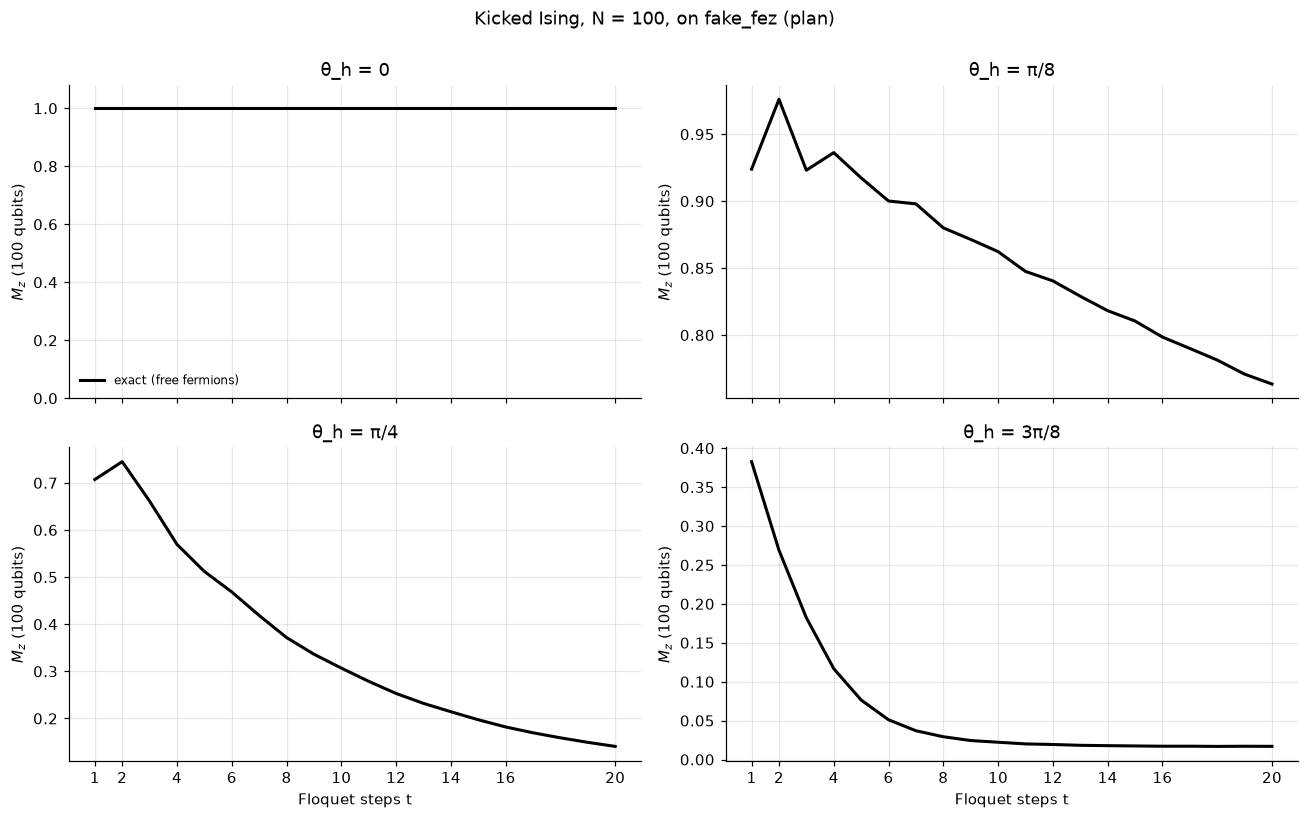

In [20]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7.4), sharex=True)
tt = np.array(T_KI)
for ax, lab in zip(axes.flat, TH):
    tf = np.arange(1, 21)
    ex_fine = [il.free_fermion_profile(N_KI, t, TH[lab])[0].mean() for t in tf] if lab != "0" else np.ones_like(tf, float)
    ax.plot(tf, ex_fine, "-", color=COL["exact"], lw=2, label="exact (free fermions)")
    if raw and (lab, 1) in raw:
        ax.plot(tt, [raw[(lab, t)]["z"].mean() for t in tt], "o:", color=COL["raw"], ms=4, label="raw QPU (no mitigation)")
    if HAVE_HW:
        if "nf_z" in hw[lab]:
            ax.plot(tt, hw[lab]["nf_z"][:, :, 0].mean(1), "s--", color="#1f77b4", ms=4, label="QPU λ=1: twirl + TREX + DD")
        mz = hw[lab]["zne_z"].mean(1); err = np.sqrt((hw[lab]["std_z"]**2).sum(1)) / N_KI
        ax.errorbar(tt, mz, yerr=err, fmt="D-", color=COL["hw"], ms=5, capsize=2, label="QPU + ZNE")
    ax.set_title(f"θ_h = {lab}"); ax.set_ylabel(r"$M_z$ (100 qubits)")
for ax in axes[1]:
    ax.set_xlabel("Floquet steps t")
for ax in axes.flat:
    ax.set_xticks([1, 2, 4, 6, 8, 10, 12, 14, 16, 20])
axes[0, 0].legend(fontsize=8); axes[0, 0].set_ylim(0.0, 1.08)
fig.suptitle(f"Kicked Ising, N = 100, on {backend_name}", y=1.0)
plt.tight_layout(); savefig("a1_mz_100q"); plt.show()

In [21]:
if HAVE_HW:
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.9))
    for lab, c in zip(TH, ("#7f7f7f", "#2ca02c", "#1f77b4", "#d62728")):
        ex = [exact_ki[(lab, t)]["zz"].mean() for t in T_KI]
        axes[0].plot(tt, ex, "-", color=c, lw=1.5)
        axes[0].plot(tt, hw[lab]["zne_zz"].mean(1), "D", color=c, ms=5, label=f"θ_h={lab}")
        if "nf_zz" in hw[lab]:
            axes[0].plot(tt, hw[lab]["nf_zz"][:, :, 0].mean(1), "x", color=c, ms=5)
    axes[0].set_xlabel("Floquet steps t"); axes[0].set_ylabel(r"$\overline{\langle Z_iZ_{i+1}\rangle}$")
    axes[0].set_title("nearest-neighbour correlator: lines exact, ◆ ZNE, × λ=1"); axes[0].legend(fontsize=8)
    # site-resolved profile at one depth: does the device resolve the boundary physics?
    t_show = 6; k = T_KI.index(t_show)
    axes[1].plot(range(N_KI), exact_ki[("π/4", t_show)]["z"], "-", color=COL["exact"], lw=2, label="exact")
    axes[1].plot(range(N_KI), hw["π/4"]["zne_z"][k], ".", color=COL["hw"], label="QPU + ZNE")
    if raw:
        axes[1].plot(range(N_KI), raw[("π/4", t_show)]["z"], ".", color=COL["raw"], alpha=0.6, label="raw QPU")
    axes[1].set_xlabel("site i"); axes[1].set_ylabel(r"$\langle Z_i\rangle$")
    axes[1].set_title(f"site-resolved profile, θ_h=π/4, t={t_show} (edges differ from the bulk)")
    axes[1].legend(fontsize=8)
    plt.tight_layout(); savefig("a2_zz_profile"); plt.show()

**Noiseless vs noise-model vs hardware, at 100 qubits.** Pauli noise outside the backward light cone $[c-t,c+t]$ cannot change $\langle Z_c\rangle$. So the *noisy* value of a bulk site can be simulated exactly on a $(2t+1)$-qubit window. That window is transpiled onto the matching segment of the hardware line and carries the device's own calibrated gate and readout errors (`il.noisy_bulk_z`, cached by `scripts/emulate_hw.py`). Comparing that prediction with the QPU tells us how much of the hardware noise the calibration data explains. On the hardware side we average the bulk sites $t<i<N-1-t$, which all share one exact value.

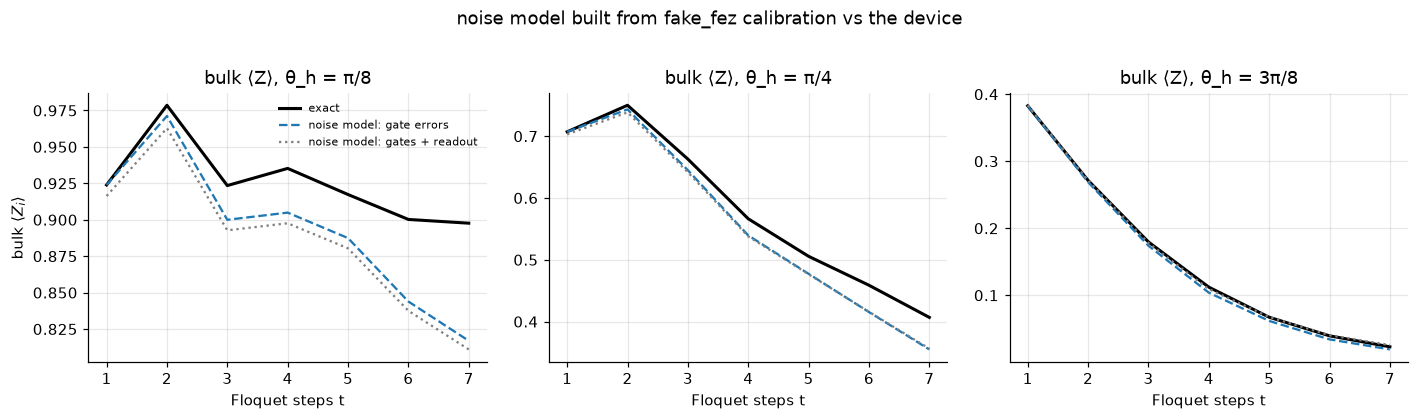

In [22]:
emu_path = RESULTS / "noisy_emulation.json"
if emu_path.exists():
    emu = json.load(open(emu_path)); te = emu["t"]
    labs = ["π/8", "π/4", "3π/8"]
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.7))
    for ax, lab in zip(axes, labs):
        a = list(TH).index(lab)
        ex = [exact_ki[(lab, t)]["z"][N_KI // 2] for t in te]
        ax.plot(te, ex, "-", color=COL["exact"], lw=2, label="exact")
        ax.plot(te, [r[a] for r in emu["gates_only"]], "--", color="#1f77b4", label="noise model: gate errors")
        ax.plot(te, [r[a] for r in emu["with_readout"]], ":", color="grey", label="noise model: gates + readout")
        if HAVE_HW:
            ks = [T_KI.index(t) for t in te]
            bulk = lambda t: slice(t + 1, N_KI - 1 - t)
            if "nf_z" in hw[lab]:
                ax.plot(te, [hw[lab]["nf_z"][k, bulk(t), 0].mean() for k, t in zip(ks, te)], "s", color="#1f77b4", label="QPU λ=1 (twirl+TREX+DD)")
            ax.plot(te, [hw[lab]["zne_z"][k, bulk(t)].mean() for k, t in zip(ks, te)], "D", color=COL["hw"], label="QPU + ZNE")
            if raw and (lab, te[0]) in raw:
                ax.plot(te, [raw[(lab, t)]["z"][bulk(t)].mean() for t in te], "o", color=COL["raw"], label="QPU raw")
        ax.set_title(f"bulk ⟨Z⟩, θ_h = {lab}"); ax.set_xlabel("Floquet steps t")
    axes[0].set_ylabel(r"bulk $\langle Z_i\rangle$"); axes[0].legend(fontsize=7)
    plt.suptitle(f"noise model built from {emu['backend']} calibration vs the device", y=1.02)
    plt.tight_layout(); savefig("a5_noise_model_vs_qpu"); plt.show()
else:
    print("results/noisy_emulation.json not found (run scripts/emulate_hw.py)")

### 3.4 Clifford-point certification: does the mitigated device return exactly +1?

At $\theta_h=\pi/2$ the circuit is Clifford. The evolved stabiliser $S_c(t)=U Z_c U^\dagger$ is a Pauli string of weight $2t-1$ with $\langle S_c\rangle=+1$ exactly, at any size. This is the hardest observable we measure: it is sensitive to an error **anywhere in its growing support**. Its decay with weight is a direct readout of the device's error per light-cone layer, and ZNE should restore it towards 1.

In [23]:
if HAVE_HW:
    ncl = [i for i, m in enumerate(meta_A) if m["kind"] == "clifford"]
    fig, ax = plt.subplots(figsize=(6.6, 3.8))
    for j, c in enumerate(meta_A[ncl[0]]["centers"]):
        wts = [meta_A[i]["weights"][j] for i in ncl]
        ev = [get(i, "evs")[j] for i in ncl]; sd = [get(i, "stds")[j] for i in ncl]
        ax.errorbar(wts, ev, yerr=sd, fmt="D-", capsize=2, color=COL["hw"] if j == 0 else "#ff9896",
                    label=f"QPU + ZNE, centre {c}")
        if f"p{ncl[0]}_evs_noise_factors" in dA:
            ax.plot(wts, [get(i, "evs_noise_factors")[j][0] for i in ncl], "s--", color="#1f77b4" if j == 0 else "#aec7e8",
                    label=f"QPU λ=1, centre {c}")
    ax.axhline(1, color="k", lw=1.5, label="exact (+1)")
    ax.set_xlabel("stabiliser weight 2t−1"); ax.set_ylabel(r"$\langle S_c(t)\rangle$")
    ax.set_title("Clifford-point check on 100 qubits"); ax.legend(fontsize=7.5)
    plt.tight_layout(); savefig("a3_clifford"); plt.show()
    print("t      :", [meta_A[i]["t"] for i in ncl])
    for j, c in enumerate(meta_A[ncl[0]]["centers"]):
        print(f"<S_{c}> :", np.round([get(i, 'evs')[j] for i in ncl], 3))

### 3.5 Long-range correlations from raw bitstrings

The Sampler shots give the full 100-bit snapshot of every run. From them we read off $\langle Z_iZ_j\rangle$ at **any** distance, after inverting each qubit's readout channel, and compare with exact Pfaffians. Short distances probe local error rates. The decay with distance is the physics: the correlations of a free-fermion quench spreading at finite speed.

In [24]:
if raw:
    fig, ax = plt.subplots(figsize=(6.8, 3.8))
    for lab, t, c in (("π/4", 3, "#1f77b4"), ("π/4", 8, "#2ca02c"), ("3π/8", 3, "#d62728")):
        if (lab, t) not in raw:
            continue
        s = raw[(lab, t)]["spins"].astype(float)
        # measured spin = m * true spin + b, per qubit, with m = 1 - P(1|0) - P(0|1), b = P(0|1) - P(1|0)
        m_ro, b_ro = 1 - p01 - p10, p10 - p01
        z_true = (s.mean(0) - b_ro) / m_ro
        vals = []
        for r in LR:
            i, j = N_KI // 2 - r // 2, N_KI // 2 - r // 2 + r
            two = np.mean(s[:, i] * s[:, j])
            vals.append((two - m_ro[i] * b_ro[j] * z_true[i] - b_ro[i] * m_ro[j] * z_true[j] - b_ro[i] * b_ro[j])
                        / (m_ro[i] * m_ro[j]))
        ax.plot(LR, exact_ki[(lab, t)]["lr"], "-", color=c, lw=1.5)
        ax.plot(LR, vals, "o", color=c, label=f"θ_h={lab}, t={t}: raw QPU (readout-corrected)")
    ax.set_xscale("log"); ax.set_xlabel("distance r"); ax.set_ylabel(r"$\langle Z_iZ_{i+r}\rangle$")
    ax.set_title("two-point function across the 100-qubit chain (lines exact)"); ax.legend(fontsize=7.5)
    plt.tight_layout(); savefig("a4_longrange"); plt.show()

### 3.6 How far can we trust the device? The trust horizon

We call a result **trustworthy** at depth $t$ when the mitigated $M_z$ agrees with the exact value within $\max(2\sigma, 0.05)$, where $\sigma$ is the reported standard error. Below we report, for each angle, the deepest circuit that passes. We also include an internal-consistency test that needs **no exact answer**: the spread between the exponential and linear ZNE extrapolations. When that spread grows larger than the statistical error, the extrapolation is no longer reliable. In a regime with no exact solution we would rely on this test, together with the Clifford-point decay from §3.4.

In [25]:
if HAVE_HW:
    print(f"{'θ_h':>6s} " + " ".join(f"t={t:<4d}" for t in T_KI))
    horizon = {}
    for lab in TH:
        mz = hw[lab]["zne_z"].mean(1); sd = np.sqrt((hw[lab]["std_z"]**2).sum(1)) / N_KI
        dev = np.abs(mz - mz_exact_ki[lab]); ok = dev <= np.maximum(2 * sd, 0.05)
        horizon[lab] = max([t for t, o in zip(T_KI, ok) if o] or [0])
        print(f"{lab:>6s} " + " ".join(f"{d:6.3f}{'✓' if o else '✗'}" for d, o in zip(dev, ok)))
    print("\ntrust horizon (deepest passing t):", horizon)
    json.dump({"horizon": horizon}, open(RESULTS / "trust_horizon.json", "w"))
    if "nf_z" in hw["π/4"]:
        f = np.array([1, 3, 5]); y = hw["π/4"]["nf_z"].mean(1)                # (t, 3)
        lin = np.array([np.polyfit(f, yy, 1)[1] for yy in y])
        expo = np.array([math.exp(np.polyfit(f, np.log(np.clip(yy, 1e-3, None)), 1)[1]) for yy in y])
        print("\nθ_h=π/4  |exp − linear ZNE| by depth:", np.round(np.abs(expo - lin), 3))

## 4 · Performance, limitations and what we would do next

**Where each method works, and where it stops**

| Method | Works well | Breaks down | Evidence in this notebook |
|---|---|---|---|
| Lie-Trotter | Z-basis observables from a Z-product state (secretly 2nd order) | X-basis observables: first order, ~10× more CX for 0.01 accuracy | §1.3–1.4, slopes 2.00 vs 1.02 |
| Merged Suzuki-Trotter | both observables at 1st-order CX cost | — (the error constant depends on which half-steps sit outside) | §1.3 table |
| Trotter step chosen by Trotter error alone | noiseless simulation | on hardware, over-refining adds CZ errors faster than it removes Trotter error | §2.4 trade-off |
| TREX | removes readout bias for any observable | assumes readout is the only measurement error; does nothing for gate noise | §2.3 |
| ZNE (gate folding) | moderate depth, signal well above the shot noise | once the λ=5 circuit has decayed to ≈ 0, extrapolation amplifies shot noise; exponential and linear fits disagree | §2.3, §3.6 |
| Free-fermion certification | any N and any depth for the integrable kicked transverse-field Ising chain | adding a longitudinal field $h_z$ or 2D couplings breaks integrability | §3.1 |
| Light-cone certification | any local circuit, any N | cost $2^{2t+2}$: about $t\le 11$ on a laptop | §3.1 |

**Honest limitations**
* **Classical simulability.** The 100-qubit circuits are classically easy *because* we chose an integrable 1D model. That is what makes the hardware data certifiable. The same pipeline (layout search, mitigation, trust horizon) applies unchanged to a non-integrable variant, but then only the light cone ($t\lesssim 11$), the Clifford point and internal consistency checks remain.
* **The noise model.** Our fast simulator uses a Pauli approximation built from FakeFez calibration. It ignores coherent errors and crosstalk, so it cannot show the benefit of twirling or dynamical decoupling. Both are applied on the real device.
* **ZNE by gate folding** triples or quintuples circuit depth. At the deepest circuits ($t\ge 16$: ~1500–1900 CZ) the λ=5 data sits near the noise floor. Probabilistic error amplification (PEA, as in Kim *et al.*) or PEC would be the next step, at a higher QPU-time cost than our 10-minute Open Plan budget allows.
* **Statistics.** We used ~1000 shots per circuit per noise factor on hardware, so per-site values have σ ≈ 0.03–0.1 after extrapolation. Averages over 100 sites are much tighter.

**Next steps**
* Break integrability with a small longitudinal field, and certify with light-cone windows plus Clifford-perturbation checks.
* Use PEA-based ZNE with learned layer noise. Our circuits contain only two distinct CZ layers (even and odd bonds), so learning them is cheap.
* Use fractional `RZZ` gates on Heron for the TFIM: one native gate per bond instead of two CZs, halving depth.

### Headline numbers (exported to `results/summary.json` for the README and slides)

In [26]:
summary = {}
summary["thresholds_rows"] = "".join(
    f"<tr><td>{r[0]}</td><td>{r[1]}</td><td>{r[3]:.4f} ({r[2]} steps)</td><td>{r[5]}</td><td>{r[7]}</td></tr>" for r in table)
summary["compile_rows"] = "".join(
    f"<tr><td>{r[0]}</td><td>{r[1]}</td><td>{r[2]}</td><td>{r[3]}</td><td>{r[4]:.3f}</td></tr>" for r in rows21)
summary["ladder_rows"] = "".join(
    f"<tr><td>{lab}</td><td>{lad_err[('Z', k)][1]:.3f}</td><td>{lad_err[('X', k)][1]:.3f}</td></tr>"
    for k, lab in (("raw", "raw"), ("trex", "TREX"), ("zne_lin", "TREX + ZNE (linear)"), ("zne_exp", "TREX + ZNE (exp)")))
ki_meta = [m for m in meta_A if m["kind"] == "ki"]
summary["max_cz"] = max(m["ops"].get("cz", 0) for m in ki_meta)
summary["max_depth2q"] = max(m["depth_2q"] for m in ki_meta)
summary["n_ki"] = N_KI
if HAVE_HW:
    dev = {lab: np.abs(hw[lab]["zne_z"].mean(1) - mz_exact_ki[lab]) for lab in TH}
    summary["horizon_text"] = ", ".join(f"θ_h={k}: t={v}" for k, v in horizon.items())
    best = max(horizon.values())
    summary["trust_headline"] = f"t = {best} certified"
    summary["trust_sub"] = f"mitigated M_z within max(2σ, 0.05) of exact, {N_KI} qubits"
    summary["hw_takeaway"] = ("Mean |QPU+ZNE − exact| over all depths: " +
                              ", ".join(f"θ_h={lab}: {dev[lab].mean():.3f}" for lab in TH) + ".")
    summary["hw_jobs"] = f"{jobs_meta['backend']} · jobs {', '.join(jobs_meta['jobs'].values())}"
    use = jobs_meta.get("usage_s", {})
    names = {"A": "A · kicked Ising + Clifford", "B": "B · 12-spin TFIM", "C": "C · raw bitstrings"}
    prim = {"A": "EstimatorV2 (TREX, twirl, DD, ZNE)", "B": "EstimatorV2 (TREX, twirl, DD, ZNE)", "C": "SamplerV2 (raw)"}
    summary["usage_rows"] = "".join(f"<tr><td>{names[k]}</td><td>{prim[k]}</td><td>{use.get(k, '—')}</td></tr>" for k in ("A", "B", "C"))
json.dump(summary, open(RESULTS / "summary.json", "w"), indent=1, default=str)
print(json.dumps({k: v for k, v in summary.items() if not k.endswith("_rows")}, indent=1, default=str))

{
 "max_cz": 1881,
 "max_depth2q": 38,
 "n_ki": 100
}


## 5 · Credits and references

* **Tutorial:** adapted from the BasQ Qiskit Fall Fest 2026 Track 3 tutorial by Benjamin Tirado (text CC BY 4.0, code Apache 2.0). Challenge prompt by Angel Rodriguez, Benjamin Tirado and Miguel Angel Jimenez, as adapted by Quantica, IIIT-Delhi.
* **Software:** Qiskit 2.5, Qiskit Aer 0.17, Qiskit IBM Runtime 0.50 (EstimatorV2 and SamplerV2 with TREX, ZNE, twirling and DD), NumPy, SciPy and Matplotlib.
* **References:**
  * Y. Kim *et al.*, *Evidence for the utility of quantum computing before fault tolerance*, Nature **618**, 500 (2023)
  * N. Hatano and M. Suzuki, *Finding exponential product formulas of higher orders* (2005)
  * A. Childs *et al.*, *Theory of Trotter error with commutator scaling*, PRX **11**, 011020 (2021)
  * E. van den Berg *et al.*, *Model-free readout-error mitigation (TREX)*, PRA **105**, 032620 (2022)
  * K. Temme, S. Bravyi and J. Gambetta, *Error mitigation for short-depth quantum circuits*, PRL **119**, 180509 (2017)
  * Bertini, Kos and Prosen, *Exact correlation functions for dual-unitary lattice models* (kicked Ising), PRL **123**, 210601 (2019)
  * M. Wimmer, *Efficient numerical computation of the Pfaffian*, ACM TOMS **38**, 30 (2012)
* **AI tools:** Claude (Anthropic), used as a coding and writing assistant: drafting helper functions and notebook text, and debugging. Every result was checked numerically in this notebook (cross-validation to ~1e-14 and comparisons with exact solvers). The team chose the methods and reviewed all analysis.